# Segmenting synthetic cell-shaped objects

Can a small U-Net recover object masks under uneven illumination?

I generate circle-shaped objects with known masks, add local intensity variation and compare pixel thresholding with a skip-connected network. This controlled experiment makes segmentation metrics testable before using microscopy annotations.

## Run settings

The default run uses CPU and a small training budget. Set `PROJECT_FULL=1` before opening the notebook for the longer run. Both modes use the same data split and evaluation code. A short run checks the experiment; the number of epochs limits what its scores can establish.

In [3]:
import inspect
import json
import os
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import TensorDataset

root = Path.cwd()
while not (root / "pyproject.toml").exists() and root != root.parent:
    root = root.parent
if not (root / "pyproject.toml").exists():
    raise FileNotFoundError("Open this notebook inside the repository")
sys.path.insert(0, str(root / "src"))
from vision_projects.training import (
    DataSplit,
    Trainer,
    TrainConfig,
    image_grid,
    plot_history,
    predict,
    seed_everything,
)

QUICK = os.environ.get("PROJECT_FULL", "0") != "1"
EPOCHS = 6 if QUICK else 40
seed_everything(1031)
output = root / "figures" / "08_cell_segmentation"
output.mkdir(parents=True, exist_ok=True)
(root / "results").mkdir(exist_ok=True)
print({"torch": torch.__version__, "device": "cpu", "epochs": EPOCHS, "seed": 1031})

{'torch': '2.14.1+cu130', 'device': 'cpu', 'epochs': 40, 'seed': 1031}


## Images with exact masks

These are synthetic grayscale images, not biological microscopy. Independent random seeds define the three splits. Object radii and positions vary, and overlapping circles form one foreground mask. The masks describe semantic foreground; they do not distinguish individual cells.

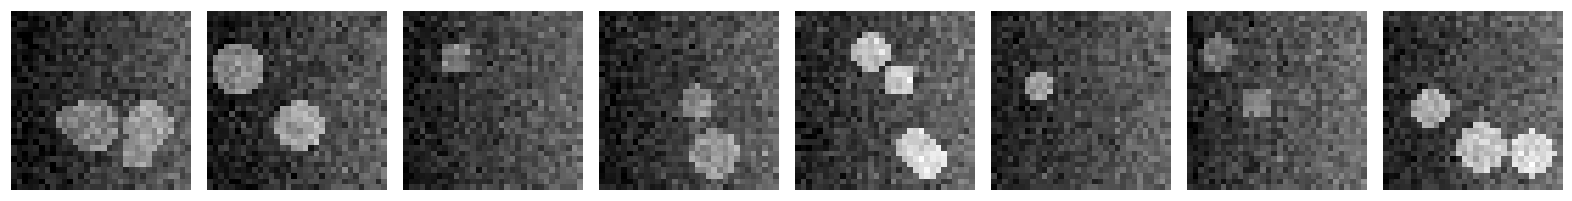

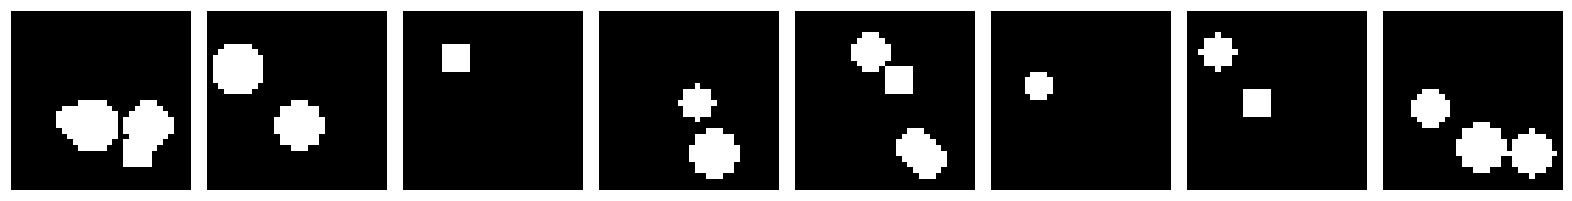

In [5]:
from vision_projects.models import TinyUNet


def synthetic_cells(count, seed):
    rng = np.random.default_rng(seed)
    rows, columns = np.mgrid[:32, :32]
    images, masks = [], []
    for _ in range(count):
        mask = np.zeros((32, 32), dtype=bool)
        for _ in range(rng.integers(1, 5)):
            cy, cx = rng.integers(5, 27, size=2)
            radius = rng.uniform(2.5, 5)
            mask |= (rows - cy) ** 2 + (columns - cx) ** 2 < radius**2
        illumination = 0.1 + columns / 100 + rng.uniform(-0.04, 0.04)
        image = (
            illumination
            + mask * rng.uniform(0.25, 0.5)
            + rng.normal(0, 0.07, mask.shape)
        )
        images.append(np.clip(image, 0, 1))
        masks.append(mask)
    return TensorDataset(
        torch.tensor(np.asarray(images)[:, None], dtype=torch.float32),
        torch.tensor(np.asarray(masks)[:, None], dtype=torch.float32),
    )


data = DataSplit(
    synthetic_cells(240 if QUICK else 2000, 1031),
    synthetic_cells(80, 1032),
    synthetic_cells(80, 1033),
)
train_loader, validation_loader, test_loader = data.loaders(32)
image_grid(data.train.tensors[0][:8], output / "cells.png")
image_grid(data.train.tensors[1][:8], output / "masks.png")

## Skip-connected segmentation

U-Net combines coarse context with spatial features from the encoder. Its output is one foreground logit per pixel. I optimize binary cross-entropy together with a soft Dice loss: $1 - (2\sum p_i y_i + \epsilon)/(\sum p_i + \sum y_i + \epsilon)$.

class TinyUNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 8, 3, padding=1), nn.ReLU(), nn.Conv2d(8, 8, 3, padding=1), nn.ReLU()
        )
        self.bottleneck = nn.Sequential(
            nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(), nn.Conv2d(16, 16, 3, padding=1), nn.ReLU()
        )
        self.decoder = nn.Sequential(nn.Conv2d(24, 8, 3, padding=1), nn.ReLU(), nn.Conv2d(8, 1, 1))

    def forward(self, images):
        skip = self.encoder(images)
        coarse = self.bottleneck(F.max_pool2d(skip, 2))
        upsampled = F.interpolate(coarse, size=skip.shape[-2:], mode="bilinear", align_corners=False)
        return self.decoder(torch.cat([skip, upsampled], dim=1))



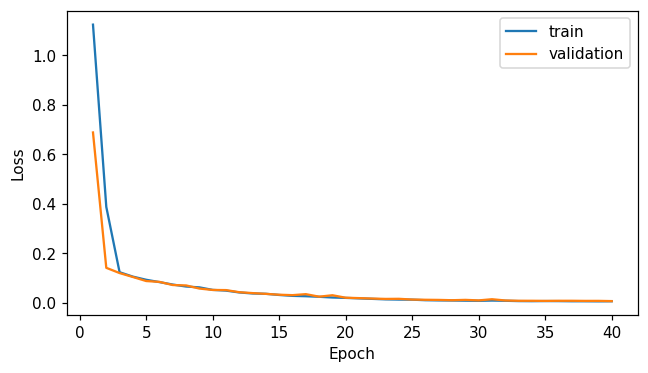

In [7]:
print(inspect.getsource(TinyUNet))


class SegmentationLoss(nn.Module):
    def forward(self, logits, targets):
        probabilities = logits.sigmoid()
        intersection = (probabilities * targets).flatten(1).sum(1)
        denominator = probabilities.flatten(1).sum(1) + targets.flatten(1).sum(1)
        soft_dice = (2 * intersection + 1e-6) / (denominator + 1e-6)
        return (
            F.binary_cross_entropy_with_logits(logits, targets) + 1 - soft_dice.mean()
        )


model = TinyUNet()
assert model(data.train.tensors[0][:2]).shape == (2, 1, 32, 32)
history = Trainer(
    model, SegmentationLoss(), TrainConfig(epochs=EPOCHS, learning_rate=0.003)
).fit(train_loader, validation_loader)
plot_history(history, output / "loss.png")

## Choose thresholds on validation

Dice and intersection-over-union are computed separately for each image and then averaged. A tiny epsilon makes two empty masks score one. Thresholds for the intensity baseline and the network are selected on validation masks.

In [9]:
def segmentation_scores(prediction, target):
    prediction, target = prediction.bool().flatten(1), target.bool().flatten(1)
    intersection = (prediction & target).sum(1).float()
    total = prediction.sum(1) + target.sum(1)
    union = (prediction | target).sum(1).float()
    return {
        "dice": float(((2 * intersection + 1e-6) / (total + 1e-6)).mean()),
        "iou": float(((intersection + 1e-6) / (union + 1e-6)).mean()),
    }


validation_logits, validation_masks = predict(model, validation_loader)
thresholds = np.linspace(0.2, 0.8, 13)
network_threshold = max(
    thresholds,
    key=lambda threshold: segmentation_scores(
        validation_logits.sigmoid() > threshold, validation_masks
    )["dice"],
)
intensity_threshold = max(
    thresholds,
    key=lambda threshold: segmentation_scores(
        data.validation.tensors[0] > threshold, validation_masks
    )["dice"],
)
print(
    {"network_threshold": network_threshold, "intensity_threshold": intensity_threshold}
)
assert (
    segmentation_scores(torch.zeros(1, 1, 2, 2), torch.zeros(1, 1, 2, 2))["dice"] == 1
)

{'network_threshold': np.float64(0.7000000000000002), 'intensity_threshold': np.float64(0.5)}


## Test masks and overlays

The synthetic test generator has the same parameter ranges as training. The evaluation therefore measures interpolation within that generator. It cannot establish performance on a microscopy acquisition protocol.

{'unet': {'dice': 0.9966403841972351, 'iou': 0.9934664964675903}, 'intensity': {'dice': 0.8465774655342102, 'iou': 0.7483924627304077}, 'network_threshold': 0.7000000000000002, 'intensity_threshold': 0.5, 'synthetic': True}


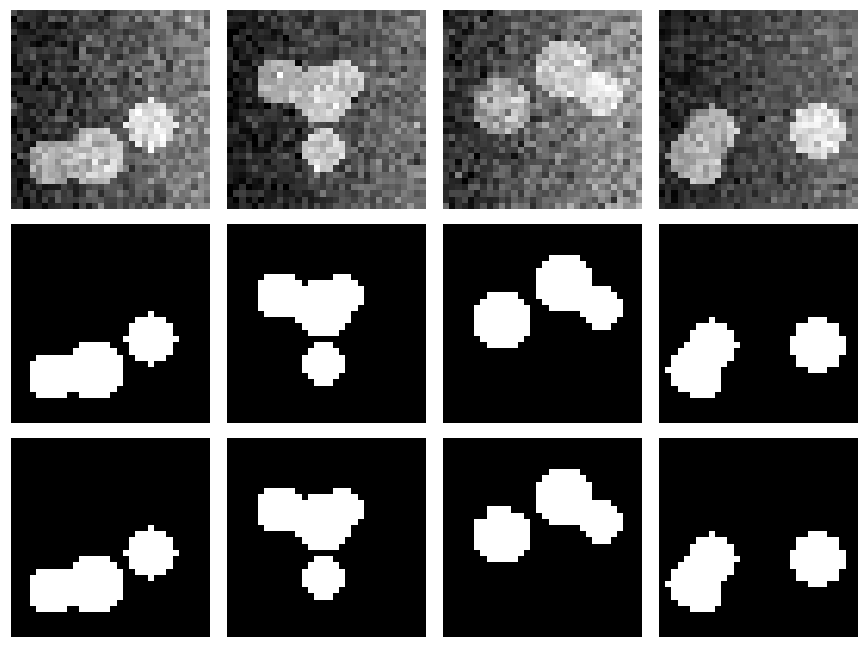

In [11]:
logits, masks = predict(model, test_loader)
predicted = logits.sigmoid() > network_threshold
baseline = data.test.tensors[0] > intensity_threshold
results = {
    "unet": segmentation_scores(predicted, masks),
    "intensity": segmentation_scores(baseline, masks),
    "network_threshold": float(network_threshold),
    "intensity_threshold": float(intensity_threshold),
    "synthetic": True,
}
print(results)
fig, axes = plt.subplots(3, 4, figsize=(8, 6))
for index in range(4):
    for row, images in enumerate([data.test.tensors[0], masks, predicted]):
        axes[row, index].imshow(images[index, 0], cmap="gray")
        axes[row, index].axis("off")
fig.tight_layout()
fig.savefig(output / "predictions.png", dpi=140)
plt.show()

## Reading the result

The network and threshold baseline answer the same semantic segmentation question. Mean image Dice gives each image equal weight, which differs from pooling all pixels. Clinical or biological claims require annotated real data and an appropriate specimen-level split.

Recorded run: After 40 epochs on 2,000 synthetic training images, the mean test Dice was 0.9966 for U-Net and 0.8466 for the validation-selected intensity threshold. The generator supplies exact masks and shares its parameter ranges across splits, which makes this a relatively well-controlled task.

In [13]:
result_path = root / "results" / "08_cell_segmentation.json"
result_path.write_text(json.dumps(results, indent=2, allow_nan=False) + "\n")
print(result_path.relative_to(root))

results/08_cell_segmentation.json


## Next experiment

Adapt the loader to paired microscopy images and masks. Split by specimen or slide before generating patches, then compare a plain encoder-decoder with the skip-connected model.

## Sources

[HSE deep learning course](https://github.com/mryab/dl-hse-ami) and its [wiki syllabus](https://wiki.cs.hse.ru/Глубинное_обучение_2022). week06_vision. [U-Net](https://arxiv.org/abs/1505.04597).

The implementations here were written for this project. Course notebooks and their saved weights are reference material; they are not redistributed.